In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn


In [ ]:
df = pd.read_csv("./csv_result-NIMS.csv")

In [6]:
df.head(10)

,id,min_fpktl,mean_fpktl,max_fpktl,std_fpktl,min_bpktl,mean_bpktl,max_bpktl,std_bpktl,min_fiat,...,mean_biat,max_biat,std_biat,duration,proto,total_fpackets,total_fvolume,total_bpackets,total_bvolume,class
0,1,40,45,50,3,40,48,113,18,361,...,20317,58785,20354,7241033,6,12,546,15,727,TELNET
1,2,40,46,56,4,40,60,98,17,324,...,16003,129174,33664,240455,6,12,553,16,975,FTP
2,3,52,226,460,207,52,890,1500,607,152,...,15731,90358,27594,6870746,6,14,3166,14,12473,HTTP
3,4,56,62,64,4,76,170,213,64,235202,...,5723,5723,0,78872373,17,4,248,4,683,DNS
4,5,101,101,101,0,195,412,634,115,1528,...,65386,428798,160266,262790503,17,21,2121,21,8659,lime
5,6,52,225,756,248,52,231,804,254,136,...,42274,154743,44619,681767,6,18,4062,17,3933,localForwarding
6,7,52,8222,16436,7849,52,62,756,41,2,...,14723,139626,25909,9998248,6,1062,8731838,680,42677,remoteForwarding
7,8,52,1469,1500,183,52,56,756,32,6,...,5484,830068,30431,5754219,6,2512,3691910,1049,59401,scp
8,9,52,1450,1500,245,52,64,756,54,6,...,13943,404559,47655,5312613,6,692,1003838,381,24701,sftp
9,10,52,146,692,178,52,157,756,172,148,...,79573,384275,102164,5168046,6,31,4530,26,4097,x11


In [7]:
list(df['class'].unique())

['TELNET',
 'FTP',
 'HTTP',
 'DNS',
 'lime',
 'localForwarding',
 'remoteForwarding',
 'scp',
 'sftp',
 'x11',
 'shell']

In [8]:
df['class'] = df['class'].replace({"HTTP":"browsing","FTP":"file_download","scp":"file_download","sftp":"file_download" ,"lime":"streaming"})

In [9]:
df.head()

,id,min_fpktl,mean_fpktl,max_fpktl,std_fpktl,min_bpktl,mean_bpktl,max_bpktl,std_bpktl,min_fiat,...,mean_biat,max_biat,std_biat,duration,proto,total_fpackets,total_fvolume,total_bpackets,total_bvolume,class
0,1,40,45,50,3,40,48,113,18,361,...,20317,58785,20354,7241033,6,12,546,15,727,TELNET
1,2,40,46,56,4,40,60,98,17,324,...,16003,129174,33664,240455,6,12,553,16,975,file_download
2,3,52,226,460,207,52,890,1500,607,152,...,15731,90358,27594,6870746,6,14,3166,14,12473,browsing
3,4,56,62,64,4,76,170,213,64,235202,...,5723,5723,0,78872373,17,4,248,4,683,DNS
4,5,101,101,101,0,195,412,634,115,1528,...,65386,428798,160266,262790503,17,21,2121,21,8659,streaming


In [10]:
df = df[df['class'] != "DNS"]

In [11]:
df['class'] = df['class'].replace({
    "shell":"remote_access",
    "x11":"remote_access",
    "remoteForwarding":"remote_access",
    "localForwarding":"remote_access",
    "TELNET":"remote_access"
    })
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 675835 entries, 0 to 713850
Data columns (total 24 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id              675835 non-null  int64 
 1   min_fpktl       675835 non-null  int64 
 2   mean_fpktl      675835 non-null  int64 
 3   max_fpktl       675835 non-null  int64 
 4   std_fpktl       675835 non-null  int64 
 5   min_bpktl       675835 non-null  int64 
 6   mean_bpktl      675835 non-null  int64 
 7   max_bpktl       675835 non-null  int64 
 8   std_bpktl       675835 non-null  int64 
 9   min_fiat        675835 non-null  int64 
 10  mean_fiat       675835 non-null  int64 
 11  max_fiat        675835 non-null  int64 
 12  std_fiat        675835 non-null  int64 
 13  min_biat        675835 non-null  int64 
 14  mean_biat       675835 non-null  int64 
 15  max_biat        675835 non-null  int64 
 16  std_biat        675835 non-null  int64 
 17  duration        675835 non-null  i

In [12]:
df.isna().sum()

,0
id,0
min_fpktl,0
mean_fpktl,0
max_fpktl,0
std_fpktl,0
min_bpktl,0
mean_bpktl,0
max_bpktl,0
std_bpktl,0
min_fiat,0


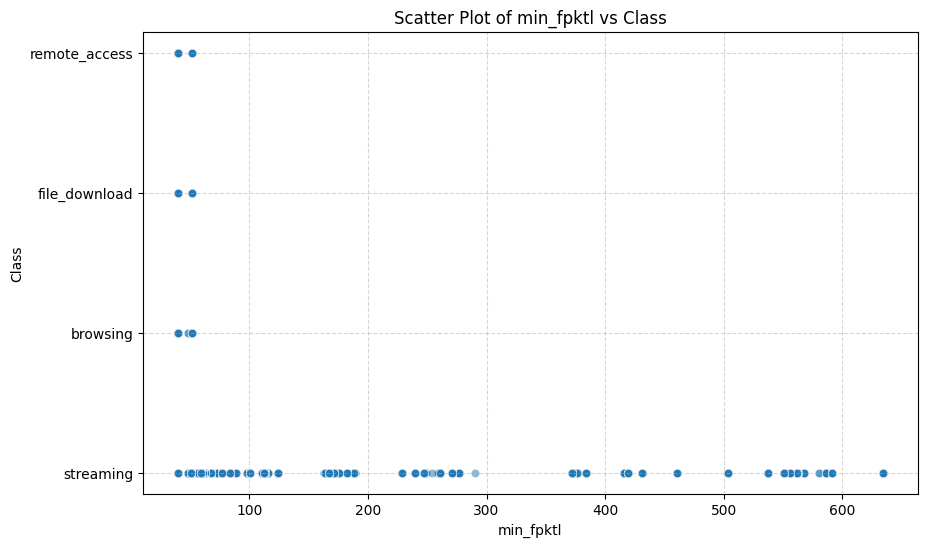

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='min_fpktl', y='class', alpha=0.5)
plt.title('Scatter Plot of min_fpktl vs Class')
plt.xlabel('min_fpktl')
plt.ylabel('Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

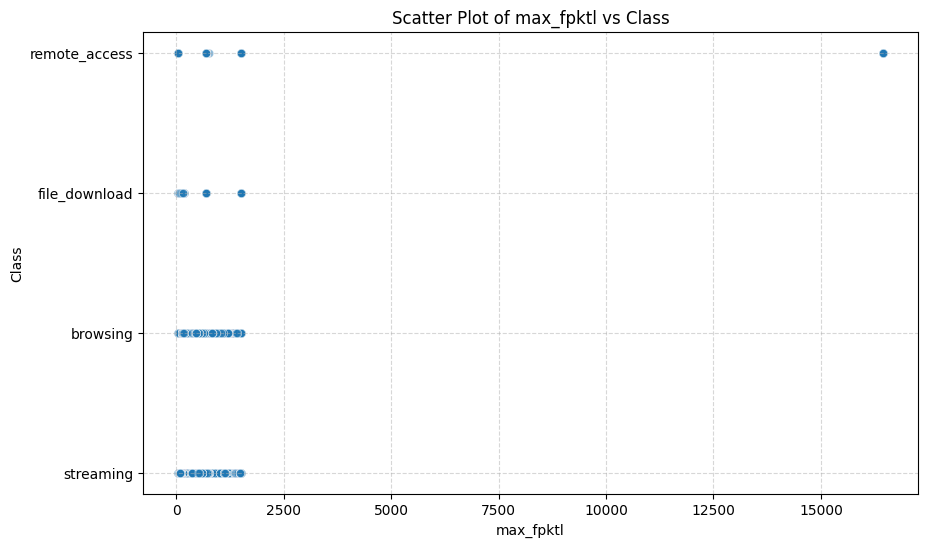

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='max_fpktl', y='class', alpha=0.5)
plt.title('Scatter Plot of max_fpktl vs Class')
plt.xlabel('max_fpktl')
plt.ylabel('Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

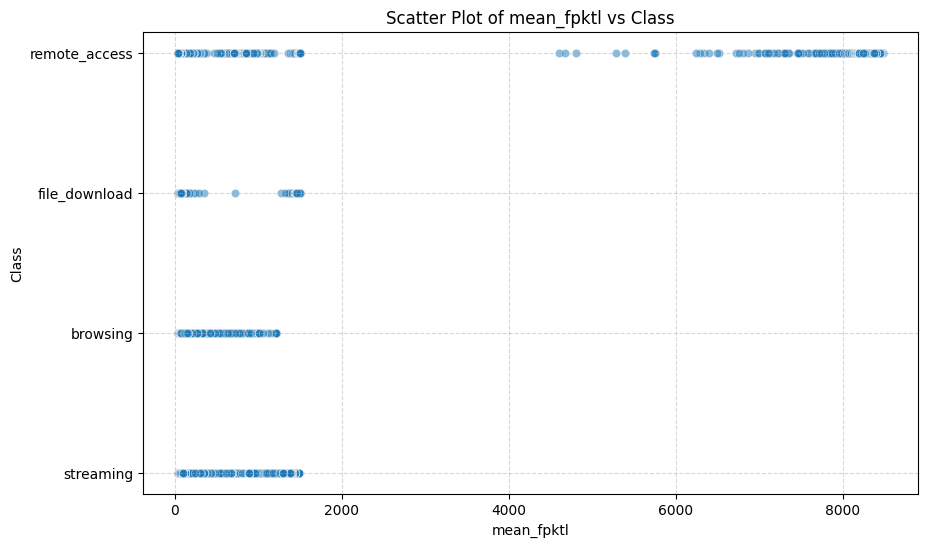

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='mean_fpktl', y='class', alpha=0.5)
plt.title('Scatter Plot of mean_fpktl vs Class')
plt.xlabel('mean_fpktl')
plt.ylabel('Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

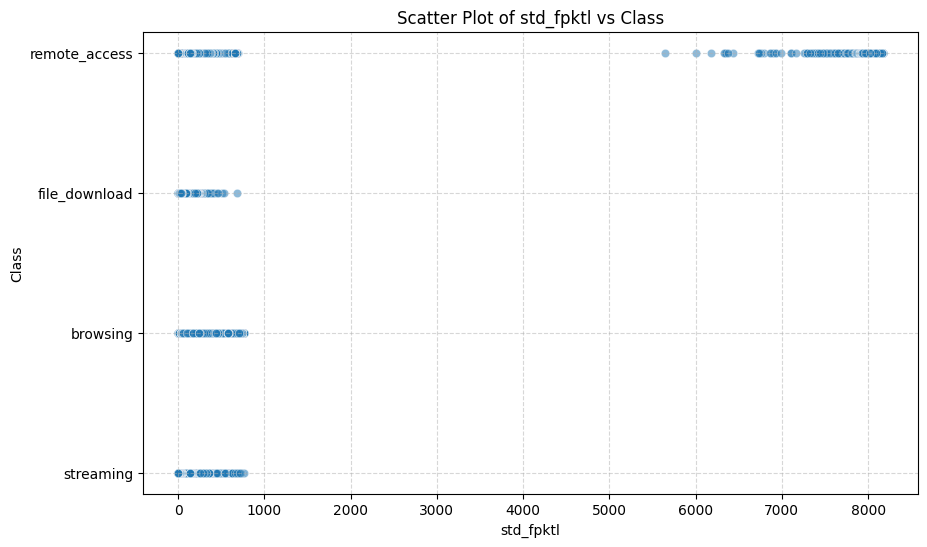

In [16]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='std_fpktl', y='class', alpha=0.5)
plt.title('Scatter Plot of std_fpktl vs Class')
plt.xlabel('std_fpktl')
plt.ylabel('Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

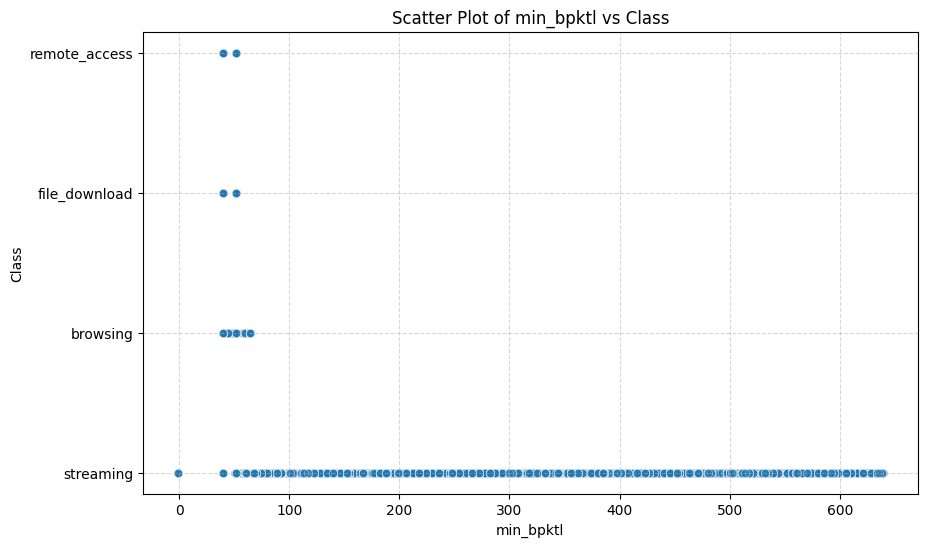

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='min_bpktl', y='class', alpha=0.5)
plt.title('Scatter Plot of min_bpktl vs Class')
plt.xlabel('min_bpktl')
plt.ylabel('Class')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

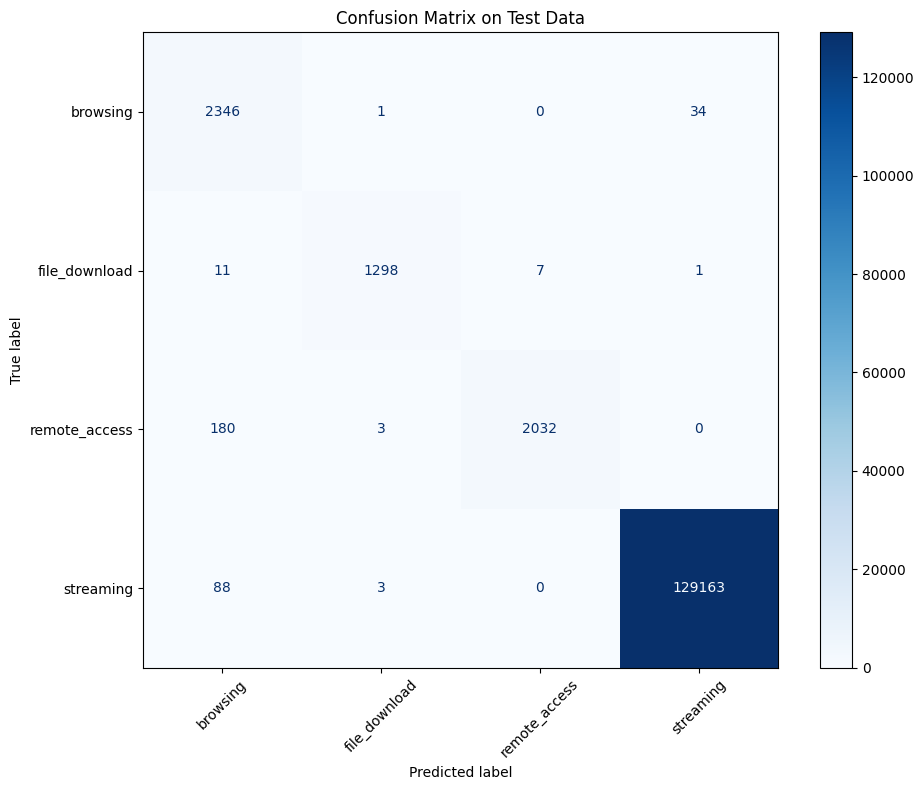

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Prepare features (X) and target (y)
X = df.drop(columns=['id', 'class'])
y = df['class']

# Split the dataset into 80% train and 20% test (shuffled)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y
)

# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Predict on the test data
y_pred = rf_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)

# Display the confusion matrix
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_model.classes_)
disp.plot(cmap='Blues', ax=plt.gca(), xticks_rotation=45)
plt.title('Confusion Matrix on Test Data')
plt.tight_layout()
plt.show()

In [19]:
from sklearn.metrics import classification_report, accuracy_score

# Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy: {accuracy:.6f}\n")

# Print classification report (precision, recall, f1-score, and support)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Overall Accuracy: 0.997573

Classification Report:
               precision    recall  f1-score   support

     browsing       0.89      0.99      0.94      2381
file_download       0.99      0.99      0.99      1317
remote_access       1.00      0.92      0.96      2215
    streaming       1.00      1.00      1.00    129254

     accuracy                           1.00    135167
    macro avg       0.97      0.97      0.97    135167
 weighted avg       1.00      1.00      1.00    135167



Training Logistic Regression model...
Logistic Regression Overall Accuracy: 0.995509

Classification Report:
               precision    recall  f1-score   support

     browsing       0.92      0.92      0.92      2381
file_download       0.96      0.98      0.97      1317
remote_access       0.93      0.94      0.93      2215
    streaming       1.00      1.00      1.00    129254

     accuracy                           1.00    135167
    macro avg       0.95      0.96      0.95    135167
 weighted avg       1.00      1.00      1.00    135167



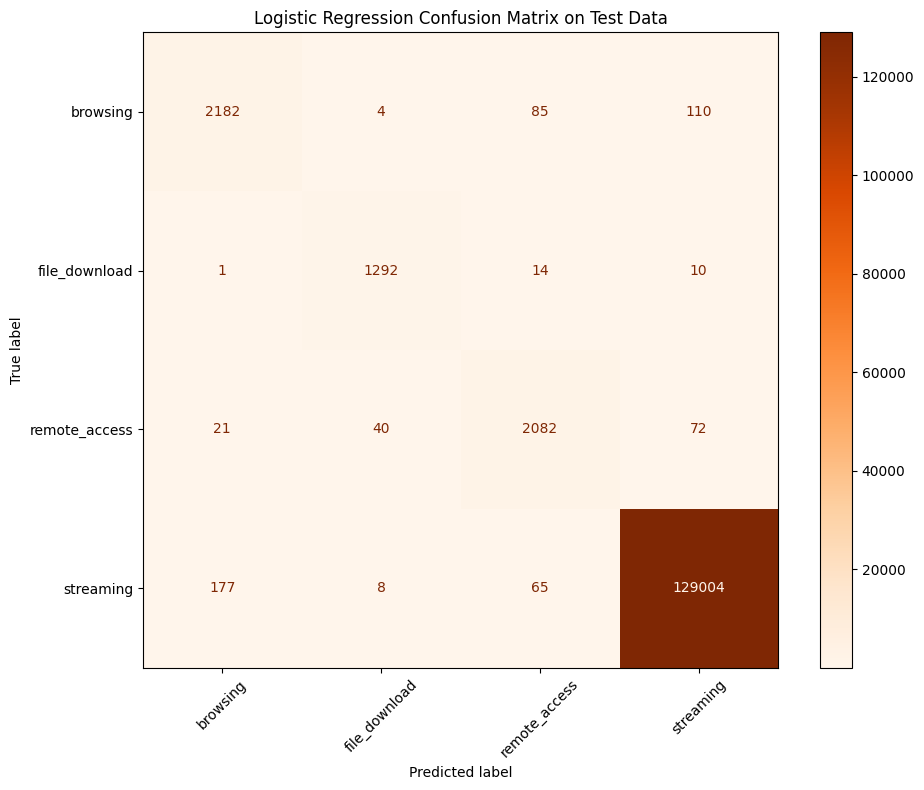

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Logistic Regression requires scaled features for optimal convergence
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
)

# Train the Logistic Regression Model
print("Training Logistic Regression model...")
lr_model.fit(X_train, y_train)

# Predict on the test data
y_pred_lr = lr_model.predict(X_test)

# Evaluate and print results
print(f"Logistic Regression Overall Accuracy: {lr_model.score(X_test, y_test):.6f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=lr_model.classes_)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=lr_model.classes_)
disp_lr.plot(cmap='Oranges', ax=plt.gca(), xticks_rotation=45)
plt.title('Logistic Regression Confusion Matrix on Test Data')
plt.tight_layout()
plt.show()

Training Decision Tree model...
Decision Tree Overall Accuracy: 0.999645

Classification Report:
               precision    recall  f1-score   support

     browsing       0.99      0.99      0.99      2381
file_download       1.00      0.99      1.00      1317
remote_access       1.00      1.00      1.00      2215
    streaming       1.00      1.00      1.00    129254

     accuracy                           1.00    135167
    macro avg       1.00      1.00      1.00    135167
 weighted avg       1.00      1.00      1.00    135167



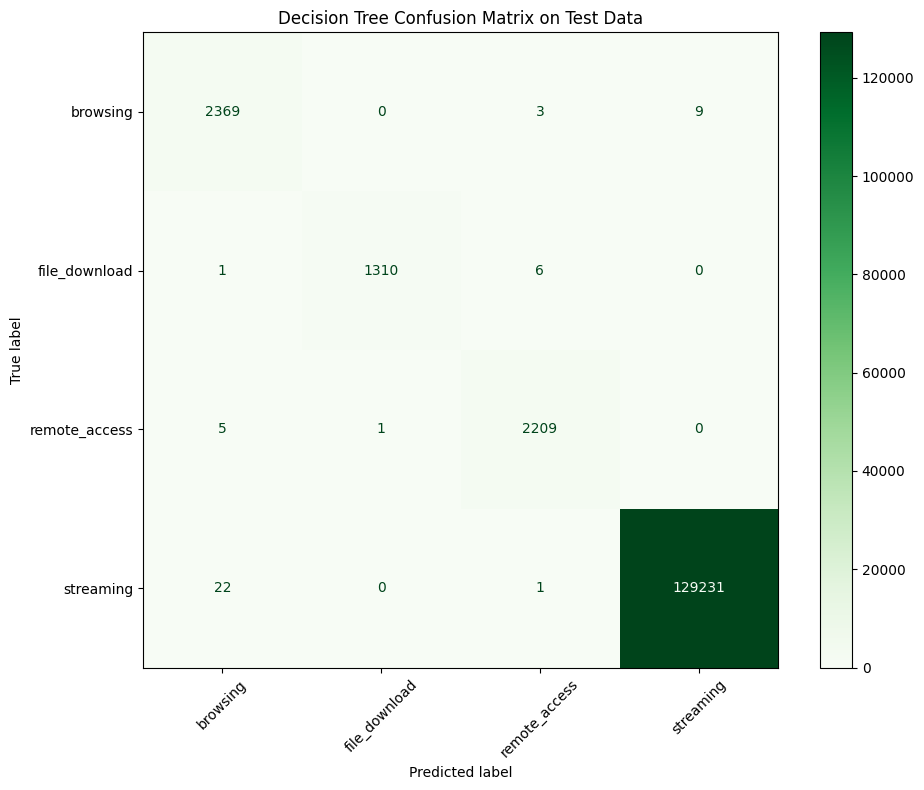

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize and train the Decision Tree Classifier
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
print("Training Decision Tree model...")
dt_model.fit(X_train, y_train)

# Predict on the test data
y_pred_dt = dt_model.predict(X_test)

# Evaluate and print results
print(f"Decision Tree Overall Accuracy: {dt_model.score(X_test, y_test):.6f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=dt_model.classes_)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=dt_model.classes_)
disp_dt.plot(cmap='Greens', ax=plt.gca(), xticks_rotation=45)
plt.title('Decision Tree Confusion Matrix on Test Data')
plt.tight_layout()
plt.show()

### Training and Evaluating XGBoost

Training XGBoost model...
XGBoost Overall Accuracy: 0.999933

Classification Report:
               precision    recall  f1-score   support

     browsing       1.00      1.00      1.00      2381
file_download       1.00      1.00      1.00      1317
remote_access       1.00      1.00      1.00      2215
    streaming       1.00      1.00      1.00    129254

     accuracy                           1.00    135167
    macro avg       1.00      1.00      1.00    135167
 weighted avg       1.00      1.00      1.00    135167



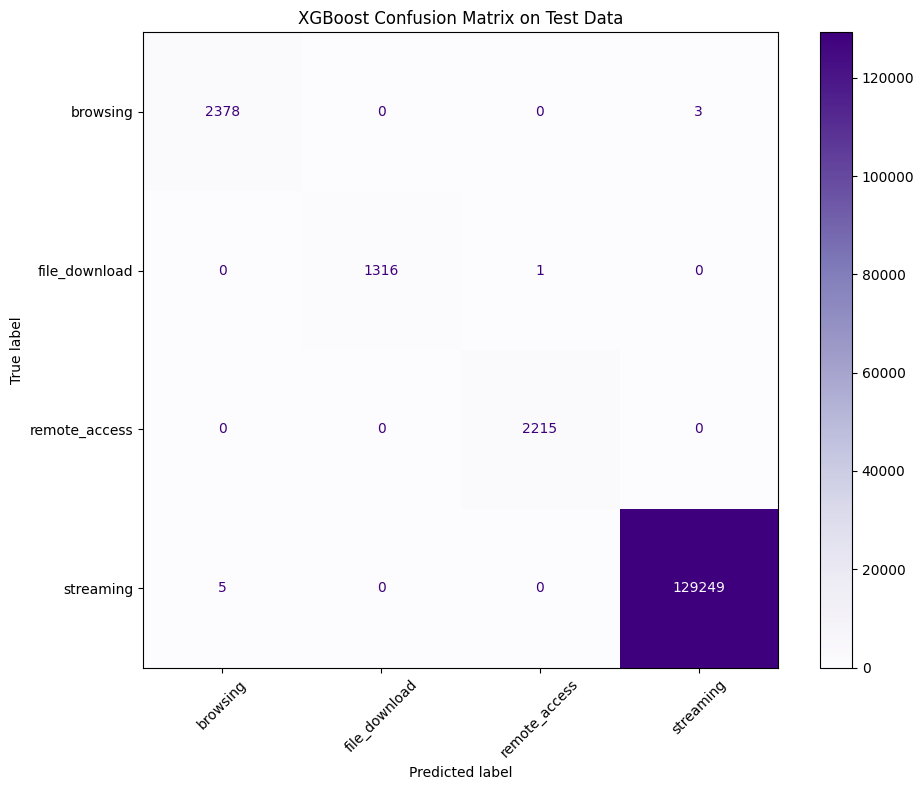

In [22]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Encode target labels to integers for XGBoost
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Initialize and train XGBoost Classifier
xgb_model = XGBClassifier(
    max_depth=5,
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost model...")
xgb_model.fit(X_train, y_train_encoded)

# Predict on test data
y_pred_encoded = xgb_model.predict(X_test)
y_pred_xgb = le.inverse_transform(y_pred_encoded)

# Evaluate results
print(f"XGBoost Overall Accuracy: {xgb_model.score(X_test, y_test_encoded):.6f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=le.classes_)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=le.classes_)
disp_xgb.plot(cmap='Purples', ax=plt.gca(), xticks_rotation=45)
plt.title('XGBoost Confusion Matrix on Test Data')
plt.tight_layout()
plt.show()

### Training and Evaluating Support Vector Machine (Linear SVM)

Training Linear SVM model (this might take a minute)...
Linear SVM Overall Accuracy: 0.995894

Classification Report:
               precision    recall  f1-score   support

     browsing       0.92      0.91      0.92      2381
file_download       0.96      0.99      0.98      1317
remote_access       0.93      0.95      0.94      2215
    streaming       1.00      1.00      1.00    129254

     accuracy                           1.00    135167
    macro avg       0.95      0.96      0.96    135167
 weighted avg       1.00      1.00      1.00    135167



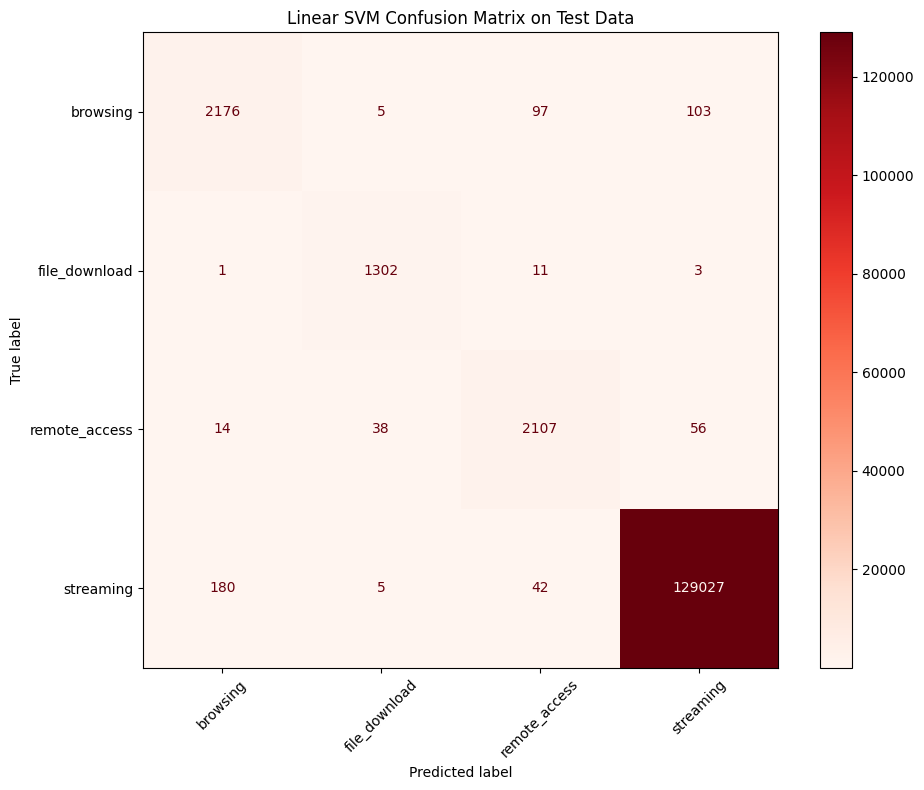

In [23]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize and train a Linear SVM with scaling
# Standard SVC (RBF kernel) is O(n^2) or O(n^3) and is extremely slow for 500k+ rows
svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(random_state=42, dual=False, max_iter=2000)
)

print("Training Linear SVM model (this might take a minute)...")
svm_model.fit(X_train, y_train)

# Predict on test data
y_pred_svm = svm_model.predict(X_test)

# Evaluate results
print(f"Linear SVM Overall Accuracy: {svm_model.score(X_test, y_test):.6f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_svm))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=svm_model.classes_)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=svm_model.classes_)
disp_svm.plot(cmap='Reds', ax=plt.gca(), xticks_rotation=45)
plt.title('Linear SVM Confusion Matrix on Test Data')
plt.tight_layout()
plt.show()

### Training and Evaluating a Neural Network (MLP Classifier)

Training Neural Network model (this may take a few moments)...
Neural Network Overall Accuracy: 0.999282

Classification Report:
               precision    recall  f1-score   support

     browsing       0.98      0.99      0.99      2381
file_download       0.99      1.00      0.99      1317
remote_access       1.00      0.99      0.99      2215
    streaming       1.00      1.00      1.00    129254

     accuracy                           1.00    135167
    macro avg       0.99      0.99      0.99    135167
 weighted avg       1.00      1.00      1.00    135167



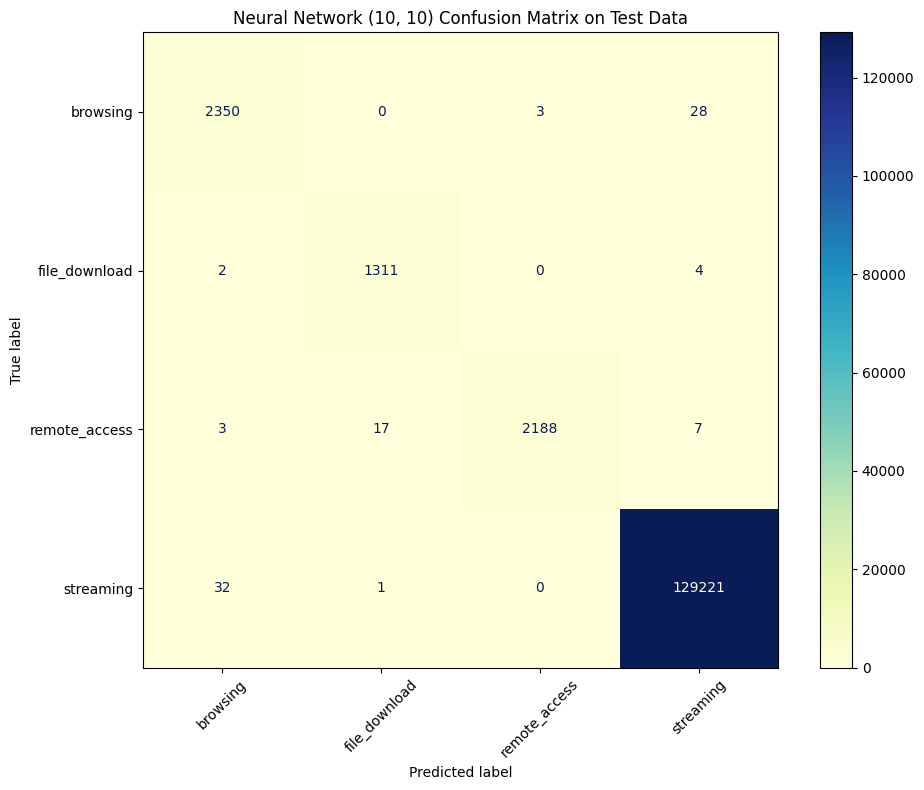

In [24]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize the MLP Classifier with 2 hidden layers of 10 neurons each
nn_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(10, 10),
        max_iter=500,
        random_state=42
    )
)

print("Training Neural Network model (this may take a few moments)...")
nn_model.fit(X_train, y_train)

# Predict on test data
y_pred_nn = nn_model.predict(X_test)

# Evaluate results
print(f"Neural Network Overall Accuracy: {nn_model.score(X_test, y_test):.6f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_nn))

# Plot confusion matrix
plt.figure(figsize=(10, 8))
cm_nn = confusion_matrix(y_test, y_pred_nn, labels=nn_model.classes_)
disp_nn = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=nn_model.classes_)
disp_nn.plot(cmap='YlGnBu', ax=plt.gca(), xticks_rotation=45)
plt.title('Neural Network (10, 10) Confusion Matrix on Test Data')
plt.tight_layout()
plt.show()

In [ ]:
rl_df = pd.read_csv("./datasets/processed/traffic_features.csv")
rl_df.head(10)

,id,min_fpktl,mean_fpktl,max_fpktl,std_fpktl,min_bpktl,mean_bpktl,max_bpktl,std_bpktl,min_fiat,...,mean_biat,max_biat,std_biat,duration,proto,total_fpackets,total_fvolume,total_bpackets,total_bvolume,class
0,1,52,157,1850,280,52,2697,19860,2644,2,...,6380,77184,12811,947218,6,62,9722,138,372150,browsing
1,2,52,115,1210,189,52,4483,61952,8521,2,...,93975,5548194,589858,11089032,6,81,9308,119,533509,browsing
2,3,52,76,676,86,52,3653,58238,5378,1,...,3596,70010,11108,13239884,6,68,5153,132,482172,browsing
3,4,52,119,675,142,52,8072,64428,15249,3,...,112093,2870509,482595,3889230,6,23,2732,35,282503,browsing
4,5,52,218,1822,415,52,932,3856,1200,932,...,31420,242163,53689,732173,6,17,3705,20,18639,browsing
5,6,40,355,1886,685,40,812,2617,1022,4093,...,33839,77230,28042,210901,6,6,2130,5,4059,browsing
6,7,40,305,1854,632,40,1113,2618,1151,3839,...,34175,77192,26162,263946,6,7,2138,6,6678,browsing
7,8,40,355,1886,685,52,814,3854,1520,13937,...,49525,75345,29832,331912,6,6,2130,5,4070,browsing
8,9,52,127,1882,240,52,2841,44620,4642,1,...,5807,74390,12210,814607,6,71,8997,129,366528,browsing
9,10,52,116,1101,177,52,3479,32820,4379,0,...,6336,152829,18825,753963,6,80,9308,120,417514,browsing


### Real-World Evaluation of Trained Models on `rl_df`

In [31]:
import pandas as pd
from sklearn.metrics import accuracy_score

# 1. Preprocess the real-world evaluation dataset (rl_df)
# Make a copy to avoid SettingWithCopy warnings
rl_eval_df = rl_df.copy()

# Map protocols to behavioral labels matching training dataset
rl_eval_df['class'] = rl_eval_df['class'].replace({
    "HTTP": "browsing",
    "FTP": "file_download",
    "scp": "file_download",
    "sftp": "file_download",
    "lime": "streaming",
    "shell": "remote_access",
    "x11": "remote_access",
    "remoteForwarding": "remote_access",
    "localForwarding": "remote_access",
    "TELNET": "remote_access"
})

# Exclude DNS if present
rl_eval_df = rl_eval_df[rl_eval_df['class'] != "DNS"]

# Separate features and targets
X_rl = rl_eval_df.drop(columns=['id', 'class'])
y_rl = rl_eval_df['class']

# 2. Evaluate all trained models
results = {}

# Random Forest
try:
    y_pred_rf = rf_model.predict(X_rl)
    results['Random Forest'] = accuracy_score(y_rl, y_pred_rf)
except NameError:
    results['Random Forest'] = "Model not found in session"

# Logistic Regression
try:
    y_pred_lr = lr_model.predict(X_rl)
    results['Logistic Regression'] = accuracy_score(y_rl, y_pred_lr)
except NameError:
    results['Logistic Regression'] = "Model not found in session"

# Decision Tree
try:
    y_pred_dt = dt_model.predict(X_rl)
    results['Decision Tree'] = accuracy_score(y_rl, y_pred_dt)
except NameError:
    results['Decision Tree'] = "Model not found in session"

# XGBoost (needs LabelEncoder target translation)
try:
    y_rl_encoded = le.transform(y_rl)
    y_pred_xgb_encoded = xgb_model.predict(X_rl)
    results['XGBoost'] = accuracy_score(y_rl_encoded, y_pred_xgb_encoded)
except NameError:
    results['XGBoost'] = "Model not found in session"

# Linear SVM
try:
    y_pred_svm = svm_model.predict(X_rl)
    results['Linear SVM'] = accuracy_score(y_rl, y_pred_svm)
except NameError:
    results['Linear SVM'] = "Model not found in session"

# Neural Network
try:
    y_pred_nn = nn_model.predict(X_rl)
    results['Neural Network'] = accuracy_score(y_rl, y_pred_nn)
except NameError:
    results['Neural Network'] = "Model not found in session"

# 3. Print the final results table
print("=== Final Real-World Accuracy Comparison ===")
for model_name, acc in results.items():
    if isinstance(acc, float):
        print(f"{model_name:25}: {acc * 100:.4f}%")
    else:
        print(f"{model_name:25}: {acc}")

=== Final Real-World Accuracy Comparison ===
Random Forest            : 3.5393%
Logistic Regression      : 3.1968%
Decision Tree            : 39.7184%
XGBoost                  : 33.1092%
Linear SVM               : 0.4313%
Neural Network           : 43.7777%


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 675835 entries, 0 to 713850
Data columns (total 24 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id              675835 non-null  int64 
 1   min_fpktl       675835 non-null  int64 
 2   mean_fpktl      675835 non-null  int64 
 3   max_fpktl       675835 non-null  int64 
 4   std_fpktl       675835 non-null  int64 
 5   min_bpktl       675835 non-null  int64 
 6   mean_bpktl      675835 non-null  int64 
 7   max_bpktl       675835 non-null  int64 
 8   std_bpktl       675835 non-null  int64 
 9   min_fiat        675835 non-null  int64 
 10  mean_fiat       675835 non-null  int64 
 11  max_fiat        675835 non-null  int64 
 12  std_fiat        675835 non-null  int64 
 13  min_biat        675835 non-null  int64 
 14  mean_biat       675835 non-null  int64 
 15  max_biat        675835 non-null  int64 
 16  std_biat        675835 non-null  int64 
 17  duration        675835 non-null  i

In [30]:
rl_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7883 entries, 0 to 7882
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              7883 non-null   int64 
 1   min_fpktl       7883 non-null   int64 
 2   mean_fpktl      7883 non-null   int64 
 3   max_fpktl       7883 non-null   int64 
 4   std_fpktl       7883 non-null   int64 
 5   min_bpktl       7883 non-null   int64 
 6   mean_bpktl      7883 non-null   int64 
 7   max_bpktl       7883 non-null   int64 
 8   std_bpktl       7883 non-null   int64 
 9   min_fiat        7883 non-null   int64 
 10  mean_fiat       7883 non-null   int64 
 11  max_fiat        7883 non-null   int64 
 12  std_fiat        7883 non-null   int64 
 13  min_biat        7883 non-null   int64 
 14  mean_biat       7883 non-null   int64 
 15  max_biat        7883 non-null   int64 
 16  std_biat        7883 non-null   int64 
 17  duration        7883 non-null   int64 
 18  proto   